# 01 · Data export and preprocessing

Builds the training dataset for Sentinel-1-only LULC segmentation over Germany.

| Step | What happens |
|---|---|
| 1 | Define 17 study areas (20.48 × 20.48 km) and their region-wise train/val/test split |
| 2 | Check Sentinel-1 coverage per orbit pass and pick one pass |
| 3 | Pilot: export and inspect one area for one month |
| 4 | Export all areas × months from Google Earth Engine (S1 composite + Dynamic World label) |
| 5 | Cut tiles into 256 × 256 patches, compute class distribution and normalisation statistics |

**Run this on the lab server**: the raw export is about 7 GB and the patches about 5 GB.
Everything is resumable: re-running a cell skips files that already exist.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from concurrent.futures import ThreadPoolExecutor, as_completed
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from tqdm.auto import tqdm
import folium
from pyproj import Transformer

from src import config as C, gee_data as G, patching as P

G.init()
CMAP = ListedColormap(C.CLASS_COLORS)
print("GEE project:", C.GEE_PROJECT, "| data dir:", C.DATA_DIR)

/home/jovyan/.local/lib/python3.11/site-packages/google/api_core/_python_package_support.py:206: FutureWarning: Package google.api_core depends on grpcio, currently installed at version 1.74.0. grpcio < 1.83.0 does not support Post-Quantum Cryptography (PQC). Support for non-PQC environments is deprecated. In April 2027, Google Cloud Python packages will raise their minimum requirements (including google-api-core, grpcio, and grpcio-status) to enforce grpcio >= 1.83.0. For more details on Google Cloud's post-quantum security migration, visit: https://cloud.google.com/security/resources/post-quantum-cryptography
  warnings.warn(


GEE project: lulc-sentinel-1 | data dir: /home/jovyan/vault/Deep Learning project/lulc-s1/data


## 1. Study areas

Five landscape types, split **by region**: a test region never contributes a single patch to training,
so test scores measure generalisation to unseen places. Munich, Leipzig and Heidelberg are kept out
entirely for the prototype case study.

In [2]:
aois = pd.DataFrame(C.AOIS).T.rename_axis("aoi").reset_index()
display(aois)
aois.groupby(["kind", "split"]).size().unstack(fill_value=0)

,aoi,lat,lon,kind,split
0,berlin,52.52,13.405,urban,train
1,hamburg,53.551,9.994,urban,train
2,cologne,50.938,6.96,urban,val
3,frankfurt,50.111,8.682,urban,test
4,magdeburger_boerde,52.06,11.4,agriculture,train
5,hildesheim_boerde,52.1,10.05,agriculture,train
6,mecklenburg,53.8,12.2,agriculture,train
7,lower_bavaria,48.85,12.6,agriculture,test
8,black_forest,47.9,8.1,forest,train
9,bavarian_forest,48.95,13.4,forest,train


split,test,train,val
kind,,,
agriculture,1,3,0
forest,1,2,1
mining,1,1,0
urban,1,2,1
water,0,2,1


In [3]:
m = folium.Map(location=[51.2, 10.4], zoom_start=6, tiles="CartoDB positron")
split_colors = {"train": "#2563eb", "val": "#f59e0b", "test": "#dc2626"}
size = C.AOI_PX * C.PIXEL_SIZE
for name, a in C.AOIS.items():
    epsg, x0, y0 = G.aoi_grid(a["lat"], a["lon"])
    to_ll = Transformer.from_crs(epsg, 4326, always_xy=True)
    lon0, lat0 = to_ll.transform(x0, y0 - size)
    lon1, lat1 = to_ll.transform(x0 + size, y0)
    folium.Rectangle([[lat0, lon0], [lat1, lon1]], color=split_colors[a["split"]], weight=2,
                     fill=True, fill_opacity=0.3, tooltip=f"{name} · {a['kind']} · {a['split']}").add_to(m)
m

/home/jovyan/.local/lib/python3.11/site-packages/folium/raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


## 2. Sentinel-1 coverage per orbit pass

Backscatter depends on the incidence angle and look direction, so ascending and descending scenes of the
same field differ. Mixing them would make month-to-month composites change for reasons that are not
land-cover change. We therefore use **one pass only**, the one with more acquisitions.
Sentinel-1C has been operational since 2025, so later months have more scenes.

In [4]:
rows = []
for name, a in tqdm(C.AOIS.items(), total=len(C.AOIS)):
    epsg, x0, y0 = G.aoi_grid(a["lat"], a["lon"])
    geom = G.grid_geometry(epsg, x0, y0, C.AOI_PX, C.AOI_PX)
    for month in ["2024-01", "2024-07", "2025-04", "2026-01"]:
        for orbit in ["ASCENDING", "DESCENDING"]:
            rows.append(dict(aoi=name, month=month, orbit=orbit, **G.month_counts(geom, month, orbit)))
coverage = pd.DataFrame(rows)
coverage.pivot_table(index="aoi", columns=["orbit", "month"], values="s1")

  0%|          | 0/17 [00:00<?, ?it/s]

orbit              ASCENDING                         DESCENDING          \
month                2024-01 2024-07 2025-04 2026-01    2024-01 2024-07   
aoi                                                                       
bavarian_forest          5.0     5.0     8.0    10.0        3.0     3.0   
berlin                   5.0     5.0     8.0    12.0       10.0    10.0   
black_forest             5.0     5.0     7.0    10.0        5.0     6.0   
cologne                  5.0     5.0     6.0    10.0        5.0     5.0   
frankfurt                5.0     5.0     6.0    11.0        5.0     6.0   
garzweiler               5.0     5.0     6.0    12.0        5.0     5.0   
hamburg                  6.0     5.0     7.0    11.0        7.0     9.0   
harz                     9.0     8.0     9.0    14.0        5.0     5.0   
hildesheim_boerde        6.0     5.0     6.0    13.0        3.0     3.0   
jade_bay                 5.0     5.0     5.0    14.0        5.0     5.0   
lake_constance           7.0     7.0     8.0    13.0        5.0     5.0   
lower_bavaria            3.0     3.0     3.0     6.0        5.0     5.0   
lusatia                  5.0     6.0    14.0    15.0        5.0     5.0   
magdeburger_boerde       6.0     5.0     6.0    11.0        5.0     5.0   
mecklenburg              5.0     5.0    10.0    10.0        5.0     5.0   
mueritz                  5.0     5.0     9.0    10.0        5.0     5.0   
thuringian_forest        6.0     5.0     7.0    13.0        5.0     5.0   

orbit                               
month              2025-04 2026-01  
aoi                                 
bavarian_forest        6.0     5.0  
berlin                17.0    15.0  
black_forest           5.0    10.0  
cologne                5.0    10.0  
frankfurt              6.0    10.0  
garzweiler             5.0    10.0  
hamburg                8.0    14.0  
harz                  11.0    13.0  
hildesheim_boerde      4.0     7.0  
jade_bay               6.0    13.0  
lake_constance         5.0    10.0  
lower_bavaria         12.0    12.0  
lusatia               13.0    13.0  
magdeburger_boerde    10.0    10.0  
mecklenburg            8.0    10.0  
mueritz               14.0    12.0  
thuringian_forest      9.0    10.0

In [5]:
print("Mean S1 scenes per area-month:")
print(coverage.groupby("orbit").s1.mean().round(1))
print("\nUsing ORBIT_PASS =", C.ORBIT_PASS, "(change in src/config.py if the table says otherwise)")

Mean S1 scenes per area-month:
orbit
ASCENDING     7.4
DESCENDING    7.5
Name: s1, dtype: float64

Using ORBIT_PASS = DESCENDING (change in src/config.py if the table says otherwise)


## 3. Pilot: one area, one month

Exports the four 1024 × 1024 tiles of Berlin for July 2024 and shows the three input channels next to the
remapped Dynamic World label. White label pixels are *ignored* in training: Dynamic World was not confident
enough (mean top-class probability < 0.5) or had no cloud-free observation that month.

In [6]:
pilot = G.export_aoi_month("berlin", C.AOIS["berlin"], "2024-07")
pilot

{'aoi': 'berlin',
 'month': '2024-07',
 'dw': 15,
 's1': 10,
 'tiles': 4,
 'status': 'ok',
 'seconds': 0.0}

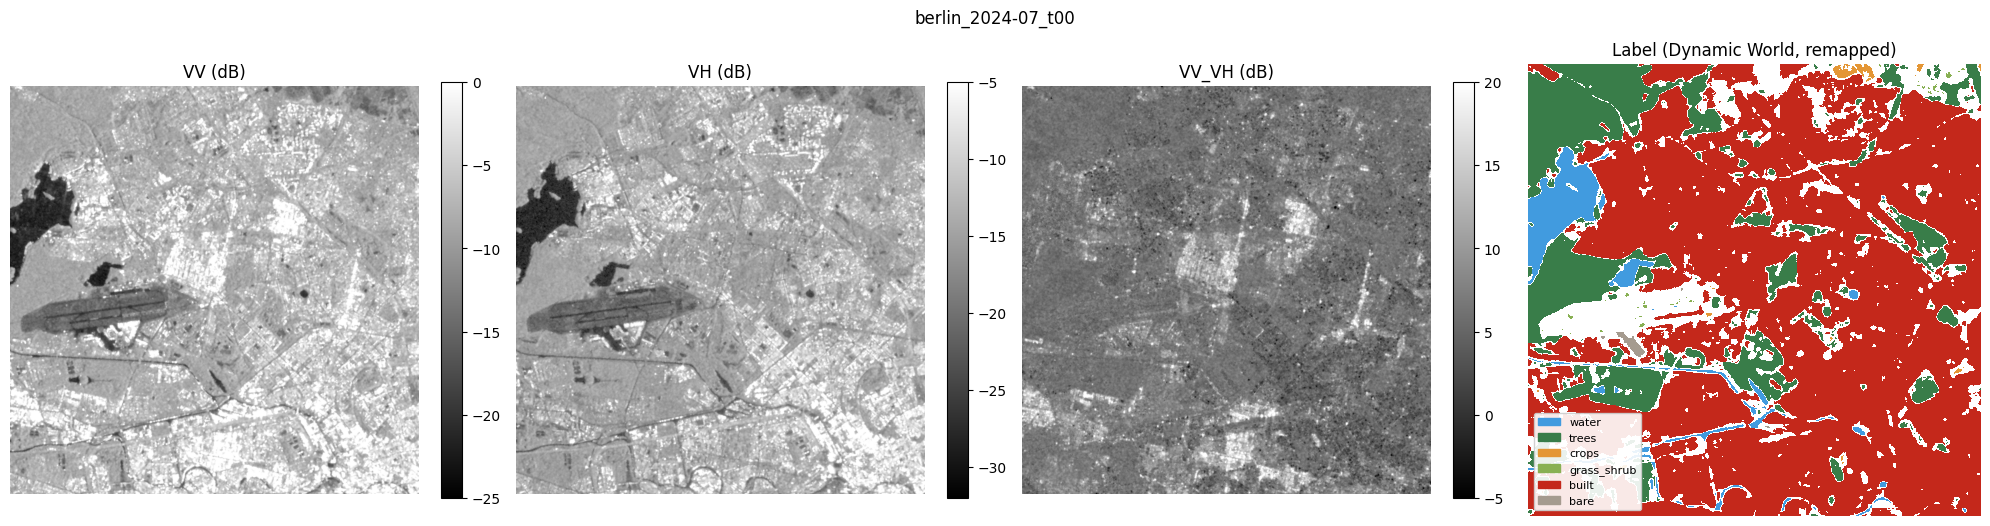

In [7]:
def show_tile(path):
    s1, label = P.load_tile(path)
    fig, ax = plt.subplots(1, 4, figsize=(20, 5.5))
    for i, (band, (lo, hi)) in enumerate(zip(C.S1_BANDS, C.CLIP_DB)):
        im = ax[i].imshow(s1[..., i], cmap="gray", vmin=lo, vmax=hi)
        ax[i].set_title(f"{band} (dB)")
        plt.colorbar(im, ax=ax[i], fraction=0.046)
    ax[3].imshow(np.ma.masked_equal(label, C.IGNORE), cmap=CMAP, vmin=0, vmax=len(C.CLASSES) - 1,
                 interpolation="nearest")
    ax[3].set_title("Label (Dynamic World, remapped)")
    ax[3].legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in C.CLASS_COLORS], C.CLASSES,
                 loc="lower left", fontsize=8, framealpha=0.9)
    for a in ax:
        a.axis("off")
    fig.suptitle(path.stem)
    plt.tight_layout()
    plt.show()

show_tile(C.RAW_DIR / "berlin" / "berlin_2024-07_t00.tif")

## 4. Full export

17 areas × 17 months (every second month, offset per year so all 12 calendar months are represented)
= 289 area-months = 1,156 tiles. At about 13 s per tile with 4 parallel workers this takes roughly
1–1.5 hours. Watch the EECU usage on the Earth Engine **Tasks / Configuration** page; the Community tier
allows 150 EECU-hours per month.

In [8]:
jobs = [(n, a, m) for n, a in C.AOIS.items() for m in C.EXPORT_MONTHS]
print(len(jobs), "area-months,", len(jobs) * (C.AOI_PX // C.TILE_PX) ** 2, "tiles")

logs = []
with ThreadPoolExecutor(max_workers=4) as pool:
    futures = {pool.submit(G.export_aoi_month, n, a, m): (n, m) for n, a, m in jobs}
    for f in tqdm(as_completed(futures), total=len(futures)):
        try:
            logs.append(f.result())
        except Exception as e:
            n, m = futures[f]
            logs.append(dict(aoi=n, month=m, status=f"error: {e}"))

logs = pd.DataFrame(logs).sort_values(["aoi", "month"])
logs.to_csv(C.DATA_DIR / "export_log.csv", index=False)
logs.status.value_counts()

289 area-months, 1156 tiles


  0%|          | 0/289 [00:00<?, ?it/s]

status
ok                             282
skipped: no S1 or DW images      7
Name: count, dtype: int64

In [9]:
print("Sentinel-1 scenes per composite:")
logs.pivot(index="aoi", columns="month", values="s1")

Sentinel-1 scenes per composite:


month,2024-01,2024-03,2024-05,2024-07,2024-09,2024-11,2025-02,2025-04,2025-06,2025-08,2025-10,2025-12,2026-01,2026-03,2026-05,2026-07,2026-09
aoi,,,,,,,,,,,,,,,,,
bavarian_forest,3,3,3,3,2,2,3,6,7,7,7,6,5,6,12,10,10
berlin,10,10,10,10,10,10,10,17,15,14,17,17,15,16,21,10,10
black_forest,5,5,6,6,4,5,5,5,10,10,10,10,10,10,14,10,10
cologne,5,5,5,5,5,5,4,5,10,9,9,10,10,10,14,10,10
frankfurt,5,5,6,6,5,5,5,6,10,10,10,10,10,10,14,10,10
garzweiler,5,5,5,5,5,5,4,5,10,9,9,10,10,10,14,10,10
hamburg,7,7,9,9,8,8,7,8,14,15,16,15,14,14,19,15,15
harz,5,5,5,5,5,5,5,11,10,10,11,12,13,13,16,10,10
hildesheim_boerde,3,3,3,3,2,2,3,4,7,7,8,8,7,7,9,10,10


In [10]:
print("Dynamic World observations per label month:")
logs.pivot(index="aoi", columns="month", values="dw")

Dynamic World observations per label month:


month,2024-01,2024-03,2024-05,2024-07,2024-09,2024-11,2025-02,2025-04,2025-06,2025-08,2025-10,2025-12,2026-01,2026-03,2026-05,2026-07,2026-09
aoi,,,,,,,,,,,,,,,,,
bavarian_forest,4,1,3,3,5,2,3,5,7,10,2,9,0,5,8,9,6
berlin,6,10,12,15,24,2,12,27,12,17,7,17,9,21,19,15,9
black_forest,2,1,4,4,8,6,1,14,20,18,8,6,7,6,13,27,23
cologne,4,4,0,6,7,4,6,20,12,14,5,6,0,13,10,10,8
frankfurt,2,1,2,4,4,2,2,8,8,7,3,3,2,5,5,9,7
garzweiler,7,4,2,8,10,5,10,25,14,17,6,8,0,16,13,13,9
hamburg,2,1,6,5,5,2,2,7,4,6,4,3,1,10,7,10,5
harz,4,2,12,7,10,1,6,20,13,19,2,6,3,11,13,19,9
hildesheim_boerde,2,0,6,5,5,1,2,10,7,9,1,3,1,6,6,10,4


## 5. Patching, splits and class distribution

* Each tile is cut into non-overlapping 256 × 256 patches.
* A patch is dropped if any S1 pixel is missing, or if fewer than 70 % of its pixels have a reliable label.
* Arrays are stored in dB (float16); clipping and normalisation happen in the training pipeline using
  `stats.json`, which is computed on the **training split only**.

In [11]:
metas = {s: P.build_split(s) for s in ["train", "val", "test"]}
pd.DataFrame({s: {"areas": m.aoi.nunique(), "patches": len(m)} for s, m in metas.items()}).T

,areas,patches
train,10,4038
val,3,989
test,4,1794


In [12]:
pd.concat(metas, names=["split"]).reset_index(0).groupby(["split", "aoi"]).size().rename("patches").to_frame()

patches
split aoi                        
test  frankfurt               406
      lower_bavaria           448
      lusatia                 351
      thuringian_forest       589
train bavarian_forest         433
      berlin                  571
      black_forest            376
      garzweiler              383
      hamburg                 370
      hildesheim_boerde       582
      lake_constance          367
      magdeburger_boerde      376
      mecklenburg             154
      mueritz                 426
val   cologne                 468
      harz                    147
      jade_bay                374

,train,val,test
class,,,
water,11.86,40.92,1.94
trees,36.11,22.98,58.81
crops,25.45,4.87,21.86
grass_shrub,0.66,0.53,0.79
built,25.86,30.69,16.59
bare,0.05,0.02,0.01


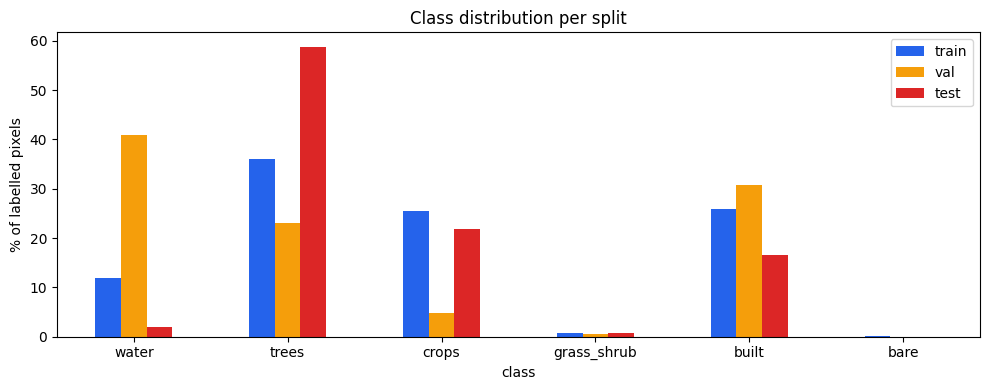

In [13]:
dist = pd.concat({s: P.class_distribution(s).set_index("class")["percent"] for s in metas}, axis=1)
display(dist.round(2))

ax = dist.plot.bar(figsize=(10, 4), color=["#2563eb", "#f59e0b", "#dc2626"], rot=0)
ax.set_ylabel("% of labelled pixels")
ax.set_title("Class distribution per split")
plt.tight_layout()
plt.show()

In [14]:
stats = P.normalisation_stats()
stats

{'bands': ['VV', 'VH', 'VV_VH'],
 'clip': [(-25.0, 0.0), (-32.0, -5.0), (-5.0, 20.0)],
 'mean': [-10.481334286514848, -17.555093079008284, 7.1583122432647865],
 'std': [4.914748402921492, 5.453761043796294, 2.3973197883878363]}

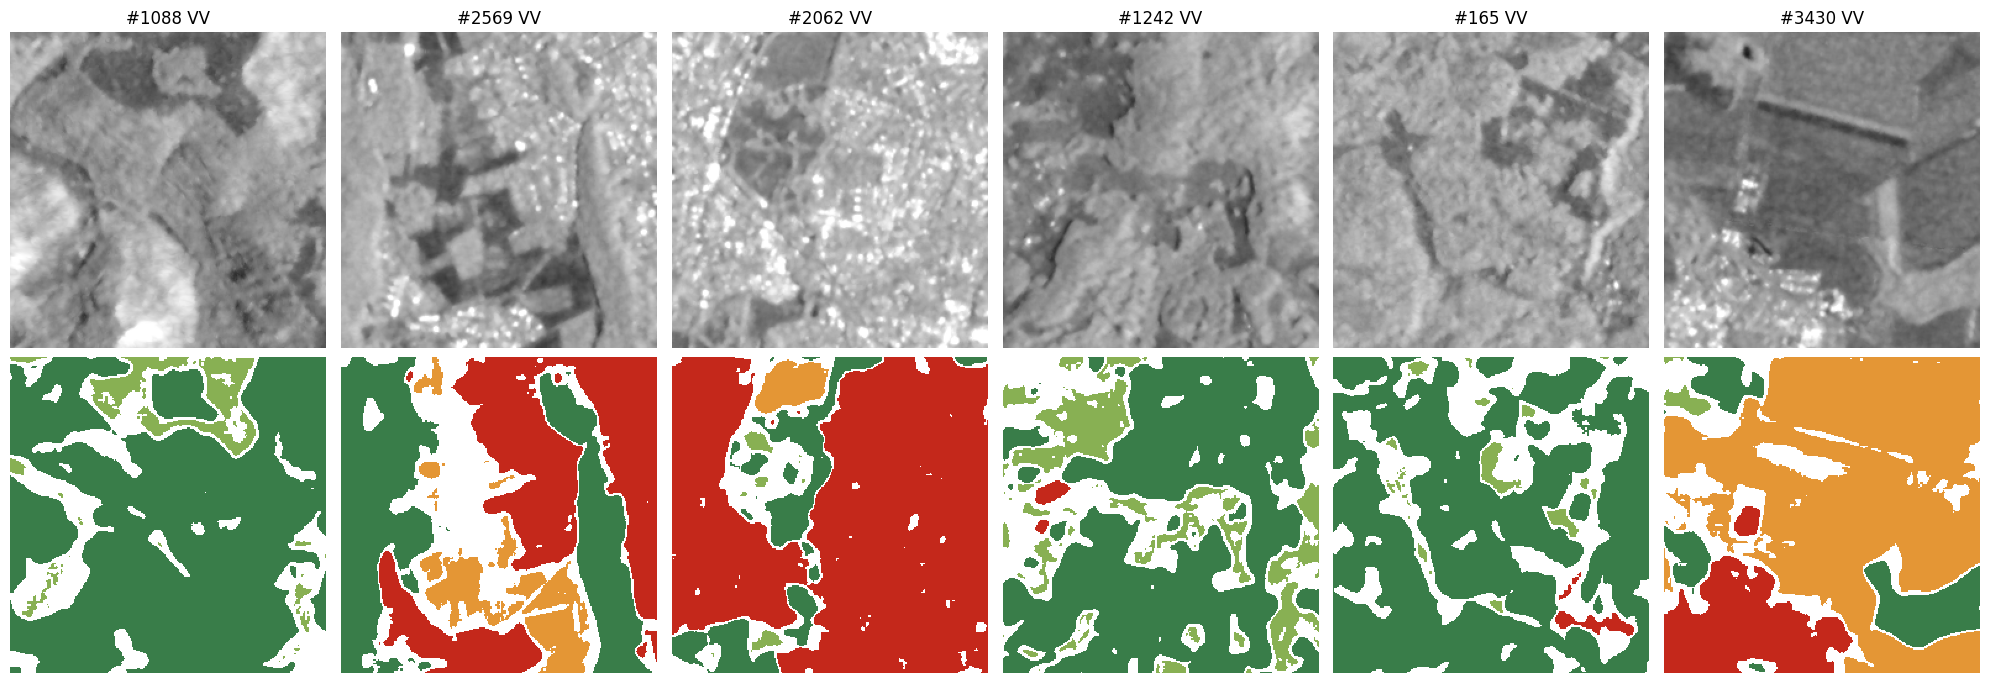

In [15]:
X = np.load(C.PATCH_DIR / "X_train.npy", mmap_mode="r")
y = np.load(C.PATCH_DIR / "y_train.npy", mmap_mode="r")
idx = np.random.default_rng(0).choice(len(X), 6, replace=False)

fig, ax = plt.subplots(2, 6, figsize=(20, 7))
for j, i in enumerate(idx):
    ax[0, j].imshow(X[i, ..., 0].astype(np.float32), cmap="gray", vmin=-25, vmax=0)
    ax[0, j].set_title(f"#{i} VV")
    ax[1, j].imshow(np.ma.masked_equal(y[i], C.IGNORE), cmap=CMAP, vmin=0, vmax=len(C.CLASSES) - 1,
                    interpolation="nearest")
for a in ax.ravel():
    a.axis("off")
plt.tight_layout()
plt.show()

## Preprocessing summary (for the report)

| Step | Where | Detail |
|---|---|---|
| Thermal noise removal, radiometric calibration (σ⁰), terrain correction (SRTM 30 m), dB conversion | GEE `COPERNICUS/S1_GRD` | Applied by GEE with the ESA SNAP toolbox |
| Scene selection | `s1_collection` | IW mode, VV+VH, 10 m GRD, **descending pass only** |
| Border noise | `_prep_scene` | VV < −30 dB masked |
| Speckle filtering | `lee_filter` | Lee filter, 5 × 5 window, ENL 4.4, applied in linear power per scene |
| Monthly compositing | `s1_monthly` | Per-pixel median of all filtered scenes in the month (also temporal multi-looking), converted back to dB; VV−VH ratio band added |
| Label matching | `dw_monthly` | Same month, same 10 m UTM grid: mean of Dynamic World class probabilities over cloud-free observations → argmax → remapped to 6 classes |
| Label quality | `load_tile` | Pixels with mean top-class probability < 0.5 or no DW observation → ignore index 255 |
| Patching | `build_split` | 256 × 256, non-overlapping; patches with S1 gaps or < 70 % labelled pixels dropped |
| Normalisation | `normalisation_stats` | Clip VV [−25, 0], VH [−32, −5], VV−VH [−5, 20] dB, then z-score with training-split mean/std |
| Splits | `config.AOIS` | By region: 10 train, 3 val, 4 test areas |
| Augmentation | training notebook | Random flips and 90° rotations (geometry only; no intensity changes that would alter backscatter meaning) |